In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

midfielders = pd.read_csv("midfielders_analysis_ready.csv")


C:\Users\Titus\AppData\Local\Temp\ipykernel_7212\161841668.py:11: DtypeWarning: Columns (0: weak_foot) have mixed types. Specify dtype option on import or set low_memory=False.
  midfielders = pd.read_csv("midfielders_analysis_ready.csv")


In [29]:
midfielder_features = [
    #Scoring
    "goals_per90",
    "xg_per90",

    #Chance Creation
    "assists_per90",
    "xag_per90",
    "per_90_minutes_kp",
    "sca_sca90",

    #Progression
    "per_90_minutes_prgp",
    "per_90_minutes_prgc",
    "per_90_minutes_1_per_3",
    "per_90_minutes_ppa",


    #Possession/passing
    "pass_completion_pct",

    #Defense
    "per_90_minutes_tackles_tkl",
    "per_90_minutes_int"

]

X = midfielders[midfielder_features].copy()

print(X.isnull().sum().sort_values(ascending=False))

missing_pct =(
    X.isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(missing_pct)
print(X.shape)




per_90_minutes_kp             1255
per_90_minutes_ppa            1255
per_90_minutes_tackles_tkl    1255
per_90_minutes_1_per_3        1255
per_90_minutes_prgp           1255
per_90_minutes_prgc           1254
pass_completion_pct           1253
xg_per90                      1252
xag_per90                     1252
sca_sca90                     1252
per_90_minutes_int               5
assists_per90                    0
goals_per90                      0
dtype: int64
per_90_minutes_kp             15.825977
per_90_minutes_ppa            15.825977
per_90_minutes_tackles_tkl    15.825977
per_90_minutes_1_per_3        15.825977
per_90_minutes_prgp           15.825977
per_90_minutes_prgc           15.813367
pass_completion_pct           15.800757
xg_per90                      15.788146
xag_per90                     15.788146
sca_sca90                     15.788146
per_90_minutes_int             0.063052
assists_per90                  0.000000
goals_per90                    0.000000
dtype: float

In [30]:

#checking for infinity values
inf_counts = pd.Series({
    col: np.isinf(X[col]).sum()
    for col in X.columns
})

print(inf_counts[inf_counts > 0])

#Replace infinity values with missing values
X = X.replace([np.inf, -np.inf], np.nan)
print("infinity values:", np.isinf(X).sum().sum())
print("Missing values:", X.isnull().sum())

#Impute missing values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)
print("NaN values:", np.isnan(X_imputed).sum())
print("Infinite values:", np.isinf(X_imputed).sum())

per_90_minutes_prgc    1
dtype: int64
infinity values: 0
Missing values: goals_per90                      0
xg_per90                      1252
assists_per90                    0
xag_per90                     1252
per_90_minutes_kp             1255
sca_sca90                     1252
per_90_minutes_prgp           1255
per_90_minutes_prgc           1255
per_90_minutes_1_per_3        1255
per_90_minutes_ppa            1255
pass_completion_pct           1253
per_90_minutes_tackles_tkl    1255
per_90_minutes_int               5
dtype: int64
NaN values: 0
Infinite values: 0


In [31]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print(X_scaled.shape)

print("Mean:")
print(X_scaled.mean(axis=0))

print("Standard deviation:")
print(X_scaled.std(axis=0))



(7930, 13)
Mean:
[-3.94248176e-17 -1.46947047e-16 -1.20962509e-16 -2.52677240e-16
 -8.96018582e-18 -2.38340943e-16  4.83850034e-16  3.04646318e-17
  1.88163902e-16 -1.07522230e-17 -1.87715893e-16 -1.23650564e-16
 -1.14690379e-16]
Standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [32]:
k_values = range(2,11)

silhouette_scores = []
davies_scores = []
inertias = []

for k in k_values:
    kmeans = KMeans(
        n_clusters = k,
        random_state=42,
        n_init=20
    )
    labels = kmeans.fit_predict(X_scaled)

    silhouette = silhouette_score(
        X_scaled,
        labels
    )

    davies = davies_bouldin_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(silhouette)
    davies_scores.append(davies)
    inertias.append(kmeans.inertia_)

    print(
        f"k={k} | "
        f"Silhouette={silhouette:.3f} |"
        f"Davies-Bouldin = {davies:.3f}"
    )




k=2 | Silhouette=0.307 |Davies-Bouldin = 1.491
k=3 | Silhouette=0.174 |Davies-Bouldin = 1.727
k=4 | Silhouette=0.177 |Davies-Bouldin = 1.565
k=5 | Silhouette=0.147 |Davies-Bouldin = 1.754
k=6 | Silhouette=0.133 |Davies-Bouldin = 1.791
k=7 | Silhouette=0.135 |Davies-Bouldin = 1.828
k=8 | Silhouette=0.137 |Davies-Bouldin = 1.815
k=9 | Silhouette=0.136 |Davies-Bouldin = 1.814
k=10 | Silhouette=0.118 |Davies-Bouldin = 1.789


In [33]:
best_k = 2

kmeans = KMeans(
    n_clusters= best_k,
    random_state=42,
    n_init=20
)

midfielders["cluster"] = kmeans.fit_predict(X_scaled)

print(
    midfielders["cluster"]
    .value_counts()
    .sort_index()
)

cluster_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=midfielder_features
)

print(cluster_centers.round(2))


cluster
0    2223
1    5707
Name: count, dtype: int64
   goals_per90  xg_per90  assists_per90  xag_per90  per_90_minutes_kp  \
0         0.71      0.92           0.84       1.14               1.13   
1        -0.28     -0.36          -0.33      -0.45              -0.44   

   sca_sca90  per_90_minutes_prgp  per_90_minutes_prgc  \
0       1.14                 0.35                 0.94   
1      -0.44                -0.14                -0.37   

   per_90_minutes_1_per_3  per_90_minutes_ppa  pass_completion_pct  \
0                    0.01                1.03                -0.43   
1                   -0.00               -0.40                 0.17   

   per_90_minutes_tackles_tkl  per_90_minutes_int  
0                       -0.56               -0.62  
1                        0.22                0.24  


C:\Users\Titus\AppData\Local\Temp\ipykernel_7212\2266588164.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  midfielders["cluster"] = kmeans.fit_predict(X_scaled)


In [34]:
for cluster in range(best_k):

    print(f"\n==== Cluster {cluster} ====")

    sample = (
        midfielders[
            midfielders["cluster"] == cluster
        ][
          [
              "player",
              "team",
              "season",
              "player_positions",
              "goals_per90",
              "assists_per90",
              "xg_per90",
              "xag_per90"
          ]
        ]
        .head(20)
        )
    print(sample)

    profile = (
        cluster_centers
        .iloc[cluster]
        .sort_values(ascending=False)
    )

    print("\nHighest features:")
    print(profile.head(6))

    print("\nLowest features:")
    print(profile.tail(6))



==== Cluster 0 ====
               player             team  season player_positions  goals_per90  \
0     Kevin De Bruyne  Manchester City    2324          CM, CAM         0.29   
1               Rodri  Manchester City    2324          CDM, CM         0.25   
3   Federico Valverde      Real Madrid    2324           CM, RW         0.06   
4      Joshua Kimmich    Bayern Munich    2324      CDM, RB, CM         0.04   
5     Bruno Fernandes   Manchester Utd    2324          CAM, CM         0.29   
6      Bernardo Silva  Manchester City    2324           CM, RW         0.21   
7     Martin Ødegaard          Arsenal    2324          CAM, CM         0.23   
8     Frenkie de Jong        Barcelona    2324          CM, CDM         0.11   
9         Luka Modric      Real Madrid    2324               CM         0.11   
10      Jamal Musiala    Bayern Munich    2324      CAM, CM, LM         0.51   
11              Pedri        Barcelona    2324               CM         0.24   
12    Jude Bellingh

In [35]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

midfielders["PC1"] = X_pca[:,0]
midfielders["PC2"] = X_pca[:,1]

print("Explained variance:")
print(pca.explained_variance_ratio_)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)


Explained variance:
[0.42646153 0.19277595]
Total explained variance: 0.6192374794335097


C:\Users\Titus\AppData\Local\Temp\ipykernel_7212\2068322458.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  midfielders["PC1"] = X_pca[:,0]
C:\Users\Titus\AppData\Local\Temp\ipykernel_7212\2068322458.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  midfielders["PC2"] = X_pca[:,1]


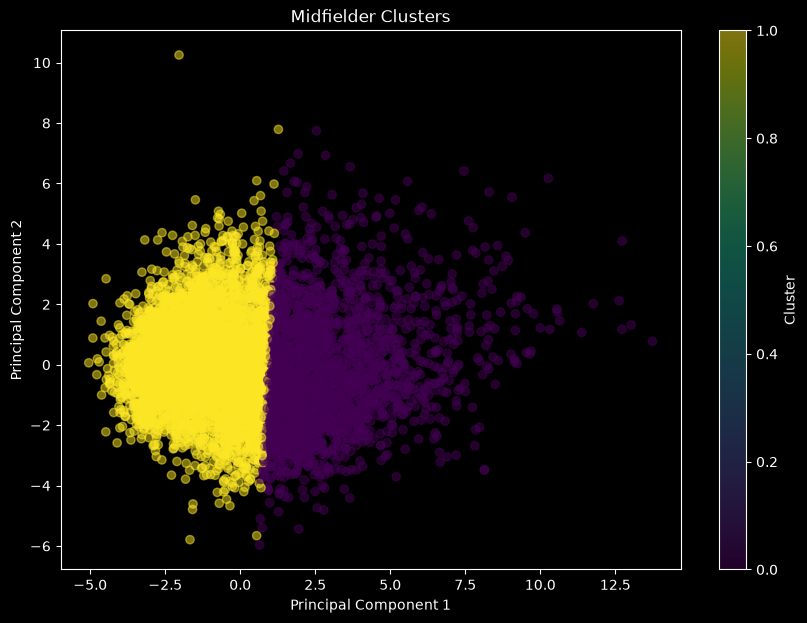

In [36]:
plt.figure(figsize=(10,7))

scatter = plt.scatter(
    midfielders["PC1"],
    midfielders["PC2"],
    c=midfielders["cluster"],
    alpha=0.5

)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Midfielder Clusters")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.show()



In [37]:
cluster_names = {
    0: "Creative / Progressive Midfielder",
    1: "Defensive / Holding Midfielder"
}

midfielders["archetype"] = (
    midfielders["cluster"]
    .map(cluster_names)
)

print(
    midfielders[
       [
        "player",
        "team",
        "player_positions",
        "cluster",
        "archetype"
    ]
   ].head(30)
)



                 player             team player_positions  cluster  \
0       Kevin De Bruyne  Manchester City          CM, CAM        0   
1                 Rodri  Manchester City          CDM, CM        0   
2              Casemiro   Manchester Utd              CDM        1   
3     Federico Valverde      Real Madrid           CM, RW        0   
4        Joshua Kimmich    Bayern Munich      CDM, RB, CM        0   
5       Bruno Fernandes   Manchester Utd          CAM, CM        0   
6        Bernardo Silva  Manchester City           CM, RW        0   
7       Martin Ødegaard          Arsenal          CAM, CM        0   
8       Frenkie de Jong        Barcelona          CM, CDM        0   
9           Luka Modric      Real Madrid               CM        0   
10        Jamal Musiala    Bayern Munich      CAM, CM, LM        0   
11                Pedri        Barcelona               CM        0   
12      Jude Bellingham      Real Madrid          CM, CAM        0   
13       Nicolo Bare

C:\Users\Titus\AppData\Local\Temp\ipykernel_7212\3634685534.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  midfielders["archetype"] = (


In [38]:
cluster_centers.to_csv("midfielder_cluster_centers.csv", index=True)
midfielders.to_csv("midfielders_clustered.csv", index=False)